In [ ]:
# Import all necessary libraries

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import spearmanr
from scipy.optimize import curve_fit
from IPython.display import display
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error

# Get UCI data
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
concrete_compressive_strength = fetch_ucirepo(id=165)   # Concrete Compressive Strength

# data (as pandas dataframes)
X = concrete_compressive_strength.data.features
y = concrete_compressive_strength.data.targets

# metadata
# print(concrete_compressive_strength.metadata)

# variable information
# print(concrete_compressive_strength.variables)

# Part 1 - Physics model

A = 74.6899 ± 0.8961   (true 75.0, -0.35σ)
B = 2.4830 ± 0.0609   (true 2.5, -0.28σ)
chi2_red = 0.9231, R^2 = 0.7521


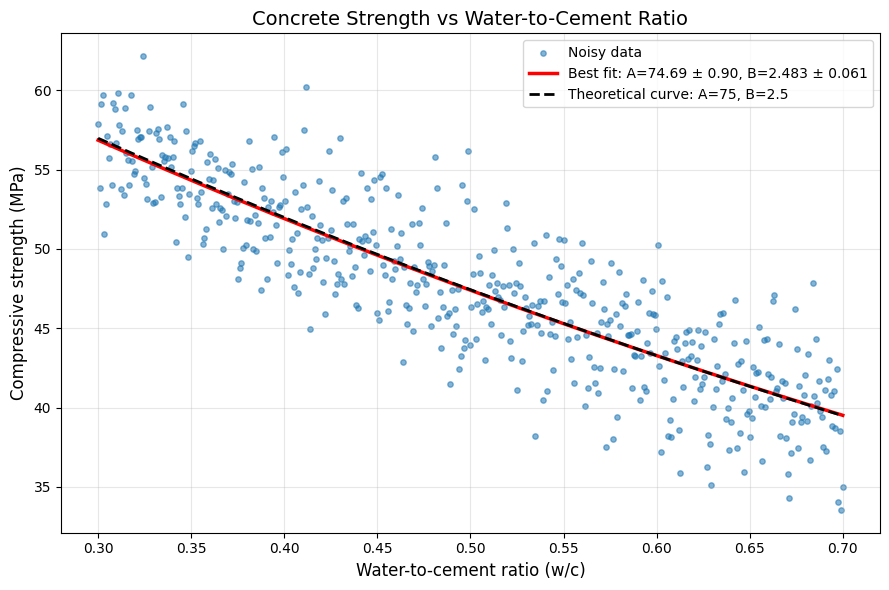

In [ ]:
'''Abrams’ law: strength = A/B^(w/c), where w/c is water divided by cement (by mass). Verify first: generate synthetic
data from A = 75, B = 2.5 with 3 MPa of noise, fit with curve fit, and show that you recover A and B within their
uncertainties.
'''


plt.close("all")   # clear any stale figures from earlier runs
plt.ioff()         # stop automatic rendering; we display once explicitly

# ---------- Part 1: generate data ----------
N, A_TRUE, B_TRUE, SIGMA = 500, 75.0, 2.5, 3.0   # Number of datapoints, A, B, Noise
rng = np.random.default_rng(42)                  # For repeatable randomness of noise

x = np.linspace(0.3, 0.7, N)
strength = A_TRUE / B_TRUE**x + rng.normal(0, SIGMA, N)   # True value + Random Gaussian noise

df = pd.DataFrame({"x": x.round(6), "A": A_TRUE, "B": B_TRUE, "strength": strength.round(6)})
df.to_csv("synthetic_strength_data.csv", index=False)     # Save CSV file

# ---------- Part 2: fit (reads the CSV back) ----------
d = pd.read_csv("synthetic_strength_data.csv")
xd, yd = d["x"].values, d["strength"].values          # extract from CSV file

def model(x, A, B):
    return A / B**x

popt, pcov = curve_fit(model, xd, yd, p0=[50, 2], sigma=np.full_like(yd, SIGMA), absolute_sigma=True)          # Find optimal A and B values with their error

(A_fit, B_fit), (dA, dB) = popt, np.sqrt(np.diag(pcov))

res = yd - model(xd, *popt)
chi2_red = np.sum((res / SIGMA) ** 2) / (N - 2)
r2 = 1 - np.sum(res**2) / np.sum((yd - yd.mean()) ** 2)

print(f"A = {A_fit:.4f} ± {dA:.4f}   (true {A_TRUE}, {(A_fit-A_TRUE)/dA:+.2f}σ)")
print(f"B = {B_fit:.4f} ± {dB:.4f}   (true {B_TRUE}, {(B_fit-B_TRUE)/dB:+.2f}σ)")
print(f"chi2_red = {chi2_red:.4f}, R^2 = {r2:.4f}")

# ---------- Part 3: single plot ----------
xs = np.linspace(0.3, 0.7, 500)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(xd, yd, s=15, alpha=0.55, label="Noisy data")
ax.plot(xs, model(xs, *popt), "r-", lw=2.5,
        label=f"Best fit: A={A_fit:.2f} ± {dA:.2f}, B={B_fit:.3f} ± {dB:.3f}")
ax.plot(xs, model(xs, A_TRUE, B_TRUE), "k--", lw=2,
        label="Theoretical curve: A=75, B=2.5")
ax.set_xlabel("Water-to-cement ratio (w/c)", fontsize=12)
ax.set_ylabel("Compressive strength (MPa)", fontsize=12)
ax.set_title("Concrete Strength vs Water-to-Cement Ratio", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

fig.savefig("fit_plot.png", dpi=300, bbox_inches="tight")
display(fig)       # render exactly once
plt.close(fig)     # prevent any second render at the end of the cell

In [ ]:
'''Check the limits: strength falls as w/c rises, and tends to A as w/c → 0'''
A_TRUE, B_TRUE, SIGMA = 75.0, 2.5, 3.0
f = lambda x, A, B: A / B**x

# Fit the existing CSV
d = pd.read_csv("synthetic_strength_data.csv")
x, y = d["x"].values, d["strength"].values
popt, pcov = curve_fit(f, x, y, p0=[50, 2], sigma=np.full_like(y, SIGMA), absolute_sigma=True)
(A_fit, B_fit), (dA, dB) = popt, np.sqrt(np.diag(pcov))

# Check 1: strength falls as w/c rises (B > 1  =>  dS/dx = -A ln(B) / B^x < 0)
xs = np.linspace(0, 1, 1001)
for name, (A, B) in {"true": (A_TRUE, B_TRUE), "fit": (A_fit, B_fit)}.items():
    s = f(xs, A, B)
    slope = -A * np.log(B) / B**xs
    print(f"[{name}] monotonic decreasing: {np.all(np.diff(s) < 0)}, max dS/dx = {slope.max():.3f} MPa (<0 required)")

print(f"B_fit - 1 = {B_fit-1:.4f} ± {dB:.4f}  ({(B_fit-1)/dB:.1f}σ above 1 -> decay confirmed)")
rho, p = spearmanr(x, y)
print(f"Data check: Spearman rho(x, strength) = {rho:.3f}, p = {p:.1e}")

# Check 2: strength -> A as w/c -> 0 (B^0 = 1)
print("\nx -> 0 limit:")
for x0 in [0.1, 0.01, 0.001, 1e-6, 0]:
    print(f"  x = {x0:<8g} true: {f(x0, A_TRUE, B_TRUE):8.4f}   fit: {f(x0, A_fit, B_fit):8.4f}")

# Uncertainty on strength at x=0 from the covariance matrix: J = [1/B^x, -A x / B^(x+1)] -> [1, 0]
J = np.array([1.0, 0.0])
sig0 = np.sqrt(J @ pcov @ J)
print(f"\nS(0) = A_fit = {f(0, A_fit, B_fit):.4f} ± {sig0:.4f}  (true A = {A_TRUE}, {(A_fit-A_TRUE)/sig0:+.2f}σ)")
print("Note: x = 0 lies outside the data range (0.3-0.7), so this is an extrapolation.")

[true] monotonic decreasing: True, max dS/dx = -27.489 MPa (<0 required)
[fit] monotonic decreasing: True, max dS/dx = -27.357 MPa (<0 required)
B_fit - 1 = 1.4830 ± 0.0609  (24.4σ above 1 -> decay confirmed)
Data check: Spearman rho(x, strength) = -0.876, p = 1.2e-159

x -> 0 limit:
  x = 0.1      true:  68.4333   fit:  68.1967
  x = 0.01     true:  74.3159   fit:  74.0137
  x = 0.001    true:  74.9313   fit:  74.6220
  x = 1e-06    true:  74.9999   fit:  74.6898
  x = 0        true:  75.0000   fit:  74.6899

S(0) = A_fit = 74.6899 ± 0.8961  (true A = 75.0, -0.35σ)
Note: x = 0 lies outside the data range (0.3-0.7), so this is an extrapolation.


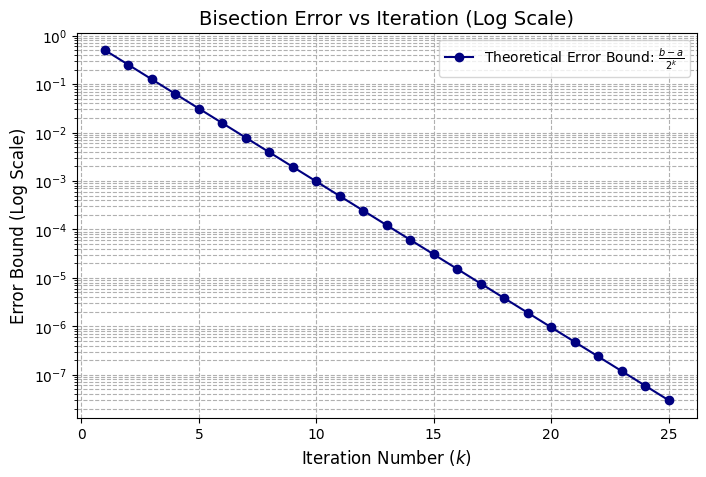

Bisection Method w/c: 0.686036
Scipy brentq w/c:     0.686036
Absolute Difference:  6.95e-09


In [ ]:


# 1. Abrams' Law Parameters & Target Strength
target_strength = 40.0

# 2. Objective Function: f(w/c) = 0 for Target 40 MPa
def f(wc):
    return (A_TRUE / (B_TRUE ** wc)) - target_strength

# 3. Reference Root using Scipy Brentq
wc_brentq = brentq(f, a=0.0, b=1.0)

# 4. Custom Bisection Method Implementation
a = 0.0
b = 1.0
max_iter = 25

iterations = []
errors = []

for k in range(1, max_iter + 1):
    c = (a + b) / 2.0
    error = (b - a) / 2.0  # Maximum theoretical error bound

    iterations.append(k)
    errors.append(error)

    # Root interval selection based on sign change
    if f(a) * f(c) < 0:
        b = c
    else:
        a = c

wc_bisection = c

# 5. Plotting Error vs Iteration on Log Scale (Rubric B4)
plt.figure(figsize=(8, 5))
plt.semilogy(iterations, errors, 'o-', color='navy', label=r'Theoretical Error Bound: $\frac{b-a}{2^k}$')
plt.title("Bisection Error vs Iteration (Log Scale)", fontsize=14)
plt.xlabel("Iteration Number ($k$)", fontsize=12)
plt.ylabel("Error Bound (Log Scale)", fontsize=12)
plt.grid(True, which="both", linestyle="--")
plt.legend()
plt.show()

# 6. Comparison Output
print(f"Bisection Method w/c: {wc_bisection:.6f}")
print(f"Scipy brentq w/c:     {wc_brentq:.6f}")
print(f"Absolute Difference:  {abs(wc_bisection - wc_brentq):.2e}")

# Part 2 - Data and Statistics

n = 425, w/c from 0.27 to 1.88
A = 75.03 ± 2.63 MPa,  B = 2.573 ± 0.131  (B-1 = 12.0σ)
corr(A,B) = 0.923,  rms = 10.57 MPa,  s = 10.59 MPa,  R² = 0.483,  mean resid = 0.152


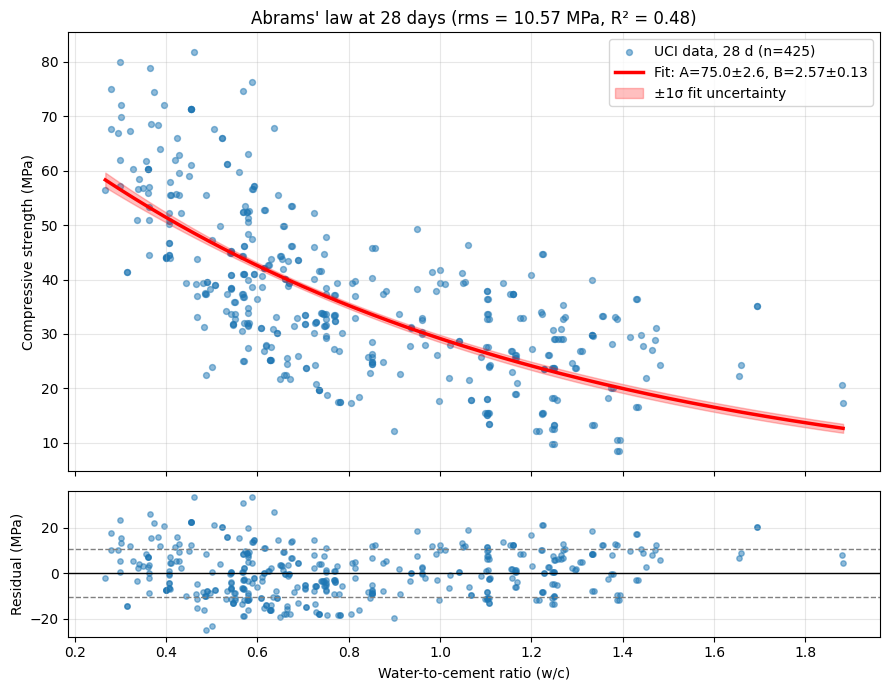

In [ ]:
!pip install -q ucimlrepo
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from ucimlrepo import fetch_ucirepo

# 1. Load UCI data, build w/c, keep only age = 28 days
raw = fetch_ucirepo(id=165)
df = pd.concat([raw.data.features, raw.data.targets], axis=1)
df.columns = df.columns.str.strip().str.lower()
df["age"], df["strength"] = df.iloc[:, 7], df.iloc[:, -1]
df["wc"] = df.iloc[:, 3] / df.iloc[:, 0]              # water / cement
d28 = df[df["age"] == 28].copy()
x, y = d28["wc"].values, d28["strength"].values

# 2. Fit Abrams' law (unweighted: real data has no known sigma)
abrams = lambda wc, A, B: A / B**wc
popt, pcov = curve_fit(abrams, x, y, p0=[100, 3], maxfev=10000)
(A, B), (dA, dB) = popt, np.sqrt(np.diag(pcov))
resid = y - abrams(x, *popt)

# 3. Quality metrics
rms = np.sqrt(np.mean(resid**2))                       # rms error (MPa)
s   = np.sqrt(np.sum(resid**2) / (len(x) - 2))         # residual sd, n-2 dof
r2  = 1 - np.sum(resid**2) / np.sum((y - y.mean())**2)
corr = pcov[0, 1] / (dA * dB)
print(f"n = {len(x)}, w/c from {x.min():.2f} to {x.max():.2f}")
print(f"A = {A:.2f} ± {dA:.2f} MPa,  B = {B:.3f} ± {dB:.3f}  (B-1 = {(B-1)/dB:.1f}σ)")
print(f"corr(A,B) = {corr:.3f},  rms = {rms:.2f} MPa,  s = {s:.2f} MPa,  R² = {r2:.3f},  mean resid = {resid.mean():.3f}")

# 4. 1σ band on the curve (error propagation with the covariance matrix)
xs = np.linspace(x.min(), x.max(), 300)
J = np.column_stack([1 / B**xs, -A * xs / B**(xs + 1)])   # [dS/dA, dS/dB]
band = np.sqrt(np.einsum("ij,jk,ik->i", J, pcov, J))
curve = abrams(xs, *popt)

# 5. Plot: data + fit (top), residuals (bottom)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.scatter(x, y, s=18, alpha=0.5, label=f"UCI data, 28 d (n={len(x)})")
a1.plot(xs, curve, "r-", lw=2.5, label=f"Fit: A={A:.1f}±{dA:.1f}, B={B:.2f}±{dB:.2f}")
a1.fill_between(xs, curve - band, curve + band, color="r", alpha=0.25, label="±1σ fit uncertainty")
a1.set(ylabel="Compressive strength (MPa)", title=f"Abrams' law at 28 days (rms = {rms:.2f} MPa, R² = {r2:.2f})")
a1.legend(); a1.grid(alpha=0.3)
a2.scatter(x, resid, s=15, alpha=0.5); a2.axhline(0, color="k", lw=1)
for k in (rms, -rms): a2.axhline(k, color="gray", ls="--", lw=1)
a2.set(xlabel="Water-to-cement ratio (w/c)", ylabel="Residual (MPa)"); a2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("abrams_28d_fit.png", dpi=300, bbox_inches="tight"); plt.show()

With fly ash:    n=217, mean=34.07, sd=13.12
Without fly ash: n=208, mean=39.54, sd=15.76

Welch t = -3.878, df = 402.9, p = 0.0001232
Mean difference = -5.47 MPa, 95% CI [-8.24, -2.69]
Cohen's d = -0.38
Reject H0 at 5%

Residuals (w/c removed): t = 0.409, p = 0.6824


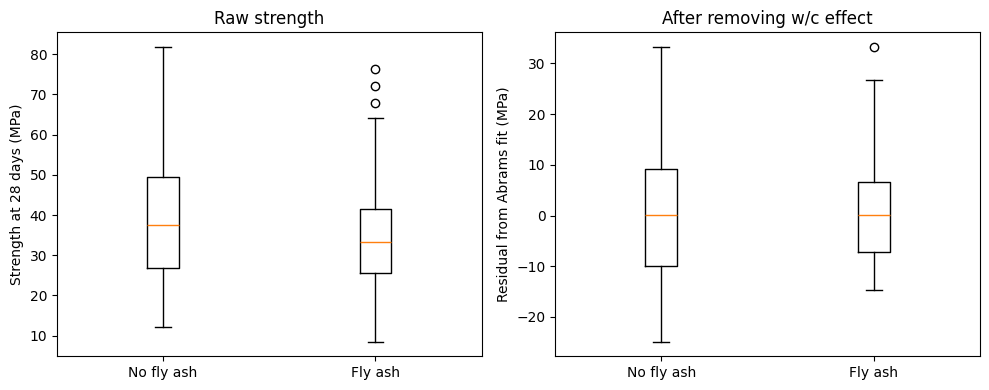

In [ ]:
!pip install -q ucimlrepo

from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# ------------------------------------------------------------------
# 1. Fetch data directly and prepare df
# ------------------------------------------------------------------
concrete_compressive_strength = fetch_ucirepo(id=165)
local_X = concrete_compressive_strength.data.features
local_y = concrete_compressive_strength.data.targets

df = pd.concat([local_X, local_y], axis=1)

# Standardize column names to lowercase and strip whitespace
df.columns = df.columns.str.strip().str.lower()

# Map columns based on their typical UCI concrete dataset positions
# 0: cement, 2: fly ash, 3: water, 7: age, -1: strength
cement_col = df.columns[0]
fly_ash_col = df.columns[2]
water_col = df.columns[3]
age_col = df.columns[7]
target_col = df.columns[-1]

# Create clean, standard columns needed for the analysis
df['age'] = df[age_col]
df['fly_ash'] = df[fly_ash_col]
df['strength'] = df[target_col]
df['wc'] = df[water_col] / df[cement_col]

# ------------------------------------------------------------------
# 2. Fix the age (28 days) and split into two groups
# ------------------------------------------------------------------
d28 = df[df["age"] == 28]
with_fa = d28.loc[d28["fly_ash"] > 0, "strength"]
without = d28.loc[d28["fly_ash"] == 0, "strength"]

print(f"With fly ash:    n={len(with_fa)}, mean={with_fa.mean():.2f}, sd={with_fa.std(ddof=1):.2f}")
print(f"Without fly ash: n={len(without)}, mean={without.mean():.2f}, sd={without.std(ddof=1):.2f}")

# ------------------------------------------------------------------
# 3. Welch t-test (equal_var=False)
# ------------------------------------------------------------------
res = stats.ttest_ind(with_fa, without, equal_var=False)
ci = res.confidence_interval(0.95)                  # CI for (mean_with - mean_without)

pooled_sd = np.sqrt((with_fa.var(ddof=1) + without.var(ddof=1)) / 2)
cohens_d = (with_fa.mean() - without.mean()) / pooled_sd

print(f"\nWelch t = {res.statistic:.3f}, df = {res.df:.1f}, p = {res.pvalue:.4g}")
print(f"Mean difference = {with_fa.mean() - without.mean():.2f} MPa, "
      f"95% CI [{ci.low:.2f}, {ci.high:.2f}]")
print(f"Cohen's d = {cohens_d:.2f}")
print("Reject H0 at 5%" if res.pvalue < 0.05 else "Fail to reject H0 at 5%")

# ------------------------------------------------------------------
# 4. Control for w/c: test the residuals of an Abrams fit
# ------------------------------------------------------------------
def abrams(wc, A, B):
    return A / B**wc

popt, _ = curve_fit(abrams, d28["wc"], d28["strength"], p0=[70, 2])
resid = d28["strength"] - abrams(d28["wc"], *popt)

r_with = resid[d28["fly_ash"] > 0]
r_without = resid[d28["fly_ash"] == 0]
res_r = stats.ttest_ind(r_with, r_without, equal_var=False)
print(f"\nResiduals (w/c removed): t = {res_r.statistic:.3f}, p = {res_r.pvalue:.4g}")

# ------------------------------------------------------------------
# 5. Plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].boxplot([without, with_fa], tick_labels=["No fly ash", "Fly ash"])
ax[0].set_ylabel("Strength at 28 days (MPa)")
ax[0].set_title("Raw strength")
ax[1].boxplot([r_without, r_with], tick_labels=["No fly ash", "Fly ash"])
ax[1].set_ylabel("Residual from Abrams fit (MPa)")
ax[1].set_title("After removing w/c effect")
plt.tight_layout()
plt.show()

# Part 3 - Data-Driven Model

In [ ]:
df = pd.concat([concrete_compressive_strength.data.features, concrete_compressive_strength.data.targets], axis=1)

# Standardize all column names to lowercase and strip whitespace
df.columns = df.columns.str.strip().str.lower()

# -- Extract columns by their known positions in UCI dataset
cement_col = df.columns[0]
water_col = df.columns[3]
age_col = df.columns[7]
target_col = df.columns[-1]

# -- Feature Engineering
df['wc'] = df[water_col] / df[cement_col]
df['log_age'] = np.log(df[age_col])

# Use all available feature columns for ML
X_ml = df.drop(columns=[target_col])
y_ml = df[target_col]

# --- PART 3.1: 5-Fold Cross-Validation Comparison ---
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("--- 5-Fold Cross-Validation (RMSE) ---")

# kNN Pipeline
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5))
])
knn_scores = -cross_val_score(knn_pipeline, X_ml, y_ml, scoring='neg_root_mean_squared_error', cv=kf)
print(f"kNN Regressor RMSE:         {knn_scores.mean():.3f} (+/- {knn_scores.std():.3f})")

# Decision Tree Regressor
dt_scores = -cross_val_score(DecisionTreeRegressor(random_state=42), X_ml, y_ml, scoring='neg_root_mean_squared_error', cv=kf)
print(f"Decision Tree RMSE:         {dt_scores.mean():.3f} (+/- {dt_scores.std():.3f})")

# Mean baseline (Null model)
mean_rmse = np.sqrt(np.mean((y_ml - y_ml.mean())**2))
print(f"Mean Baseline RMSE:         {mean_rmse:.3f}")

--- 5-Fold Cross-Validation (RMSE) ---
kNN Regressor RMSE:         6.366 (+/- 0.555)
Decision Tree RMSE:         6.413 (+/- 0.492)
Mean Baseline RMSE:         16.698
